# Midterm Project: Predicting Diabetes Disease Progression

In this project, I will build a regression model to predict how much diabetes progresses in one year, using the Diabetes dataset from scikit-learn. The dataset contains baseline medical measurements for diabetes patients, and the target is a measure of disease progression one year later.

I will follow a complete machine learning workflow:
- Load the data and check its structure
- Remove duplicates and split the data into training and test sets
- Explore the training data in detail
- Clean the data and create new features
- Train and compare several regression models
- Tune the best models with Grid Search and cross-validation
- Interpret which features affect disease progression the most


# Part 1: Review of Machine Learning Concepts

Machine learning is a way for computers to learn patterns from data and make predictions, without being given explicit rules.

Main types:
- Supervised learning: the model learns from labelled data, where the correct answer is known. It includes regression (predicting a number) and classification (predicting a category).
- Unsupervised learning: the model finds patterns in data without labels, such as grouping similar customers (clustering).
- Reinforcement learning: the model learns by trial and error, using rewards and penalties.

This project is a supervised regression problem, because the target (disease progression) is a known number.

Key components in this project:
- Features: the input measurements (age, sex, BMI, blood pressure, and six blood measurements).
- Label (target): disease progression one year later.
- Model training: the model learns the relationship between the features and the target using the training data.
- Model evaluation: I check how well the model predicts on test data it has never seen, using MSE, RMSE, MAE, and R².
- Prediction: the trained model estimates disease progression for new patients.

# Part 2: Load the Dataset and Check Its Structure

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
# Load the unscaled (raw) version
diabetes = load_diabetes(as_frame=True, scaled=False)
diab_df = diabetes.frame

In [4]:
# Give the six blood measurements meaningful names (from the dataset description)
diab_df = diab_df.rename(columns={
    "s1": "total_chol", "s2": "ldl", "s3": "hdl",
    "s4": "chol_hdl_ratio", "s5": "log_triglycerides", "s6": "blood_sugar"
})

In [5]:
print("Shape:", diab_df.shape)
display(diab_df.head())

Shape: (442, 11)


,age,sex,bmi,bp,total_chol,ldl,hdl,chol_hdl_ratio,log_triglycerides,blood_sugar,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [6]:
print("\nData types:")
print(diab_df.dtypes)


Data types:
age                  float64
sex                  float64
bmi                  float64
bp                   float64
total_chol           float64
ldl                  float64
hdl                  float64
chol_hdl_ratio       float64
log_triglycerides    float64
blood_sugar          float64
target               float64
dtype: object


In [7]:
print("\nUnique values per column:")
print(diab_df.nunique())


Unique values per column:
age                   58
sex                    2
bmi                  163
bp                   100
total_chol           141
ldl                  302
hdl                   63
chol_hdl_ratio        66
log_triglycerides    184
blood_sugar           56
target               214
dtype: int64


In [8]:
print("\nMissing values:", diab_df.isnull().sum().sum())
print("Duplicate rows:", diab_df.duplicated().sum())


Missing values: 0
Duplicate rows: 0


### Interpretation

The Diabetes dataset has 442 patients and 11 columns: 10 features and 1 target. I renamed the six blood measurements from s1 to s6 to meaningful names, based on the dataset description.

Features:
- age (years), sex, bmi (body mass index, kg/m²), and bp (average blood pressure, mm Hg)
- total_chol (total cholesterol), ldl ("bad" cholesterol), hdl ("good" cholesterol), chol_hdl_ratio (total cholesterol divided by HDL), log_triglycerides (log of blood fat level), and blood_sugar (blood sugar level)

Target: a measure of disease progression one year after these measurements were taken. Higher values mean the disease got worse.

Structure checks:
- All columns are stored as float64 (decimal numbers).
- sex has only 2 unique values (1 and 2), so it is actually a category, not a measurement. The dataset description does not say which number means male or female, so I will refer to them as sex 1 and sex 2.
- chol_hdl_ratio has only 66 unique values and appears to be mostly rounded to whole numbers.
- There are no missing values and no duplicate rows, so no rows need to be removed before splitting.

# Part 3: Split the Data into Training and Test Sets

In [9]:
X = diab_df.drop("target", axis=1)
y = diab_df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nTarget mean - train:", round(y_train.mean(), 2), "| test:", round(y_test.mean(), 2))

X_train: (353, 10) | X_test: (89, 10)

Target mean - train: 153.74 | test: 145.78


### Interpretation

I separated the 10 features (X) from the target (y) and split the data into 80% training (353 patients) and 20% testing (89 patients), using random_state=42. I did not use stratify, because the target is a continuous number.

The average disease progression is 153.74 in the training set and 145.78 in the test set. The difference is about 5%, which is acceptable for a test set of only 89 patients. From now on, I will explore only the training data, so that no decisions are based on the test set.

# Part 4: Exploratory Data Analysis (Training Data)

## 4A: Summary Statistics, Value Counts, and Target Distribution

In [10]:
train_df = X_train.copy()
train_df["target"] = y_train

# Summary statistics
display(train_df.describe().round(2))

,age,sex,bmi,bp,total_chol,ldl,hdl,chol_hdl_ratio,log_triglycerides,blood_sugar,target
count,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00,353.00
mean,48.92,1.47,26.54,94.99,188.74,114.92,49.52,4.08,4.65,91.72,153.74
std,12.76,0.50,4.39,14.08,34.73,30.42,12.78,1.30,0.52,11.68,78.06
min,19.00,1.00,18.10,62.00,110.00,41.60,22.00,2.00,3.26,58.00,25.00
25%,40.00,1.00,23.40,84.00,163.00,94.60,41.00,3.00,4.28,84.00,86.00
50%,51.00,1.00,25.90,93.00,186.00,112.80,48.00,4.00,4.63,92.00,142.00
75%,59.00,2.00,29.40,105.00,208.00,132.80,57.00,5.00,5.01,99.00,214.00
max,79.00,2.00,41.30,133.00,301.00,242.40,99.00,9.09,6.11,124.00,346.00


In [11]:
# Sex is a category: count patients in each group
print("Patients by sex:")
print(train_df["sex"].value_counts())

Patients by sex:
sex
1.0    187
2.0    166
Name: count, dtype: int64


### Interpretation: Summary Statistics and Value Counts

- age: patients are between 19 and 79 years old, with a median of 51, so most are middle-aged or older.
- sex: 187 patients are sex 1 and 166 are sex 2, so the two groups are fairly balanced.
- bmi: ranges from 18.1 to 41.3, with a median of 25.9. A BMI of 25 to 30 is classed as overweight and above 30 as obese, so the typical patient is overweight, and some are obese.
- bp (average blood pressure): ranges from 62 to 133 mm Hg, with a median of 93. This is the average pressure across the heartbeat, which is why it is lower than the usual "120/80" reading.
- Cholesterol: total cholesterol ranges from 110 to 301, LDL ("bad" cholesterol) from 41.6 to 242.4, and HDL ("good" cholesterol) from 22 to 99. The cholesterol/HDL ratio goes up to 9.09, which shows some patients have very unhealthy cholesterol levels.
- blood_sugar: ranges from 58 to 124.
- All values are within realistic medical ranges, so there are no obviously impossible values such as zero blood pressure or a BMI of 5.
- The features are on very different scales (for example, chol_hdl_ratio is around 4 while total cholesterol is around 190), so I will need to scale them before using models like Ridge and Lasso.

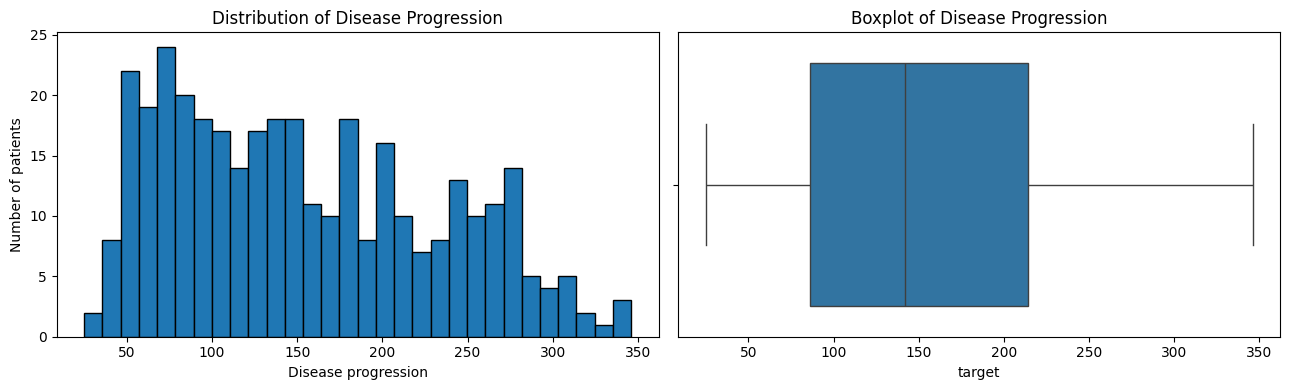

Target skewness: 0.43


In [12]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(train_df["target"], bins=30, edgecolor="black")
axes[0].set_title("Distribution of Disease Progression")
axes[0].set_xlabel("Disease progression")
axes[0].set_ylabel("Number of patients")
sns.boxplot(x=train_df["target"], ax=axes[1])
axes[1].set_title("Boxplot of Disease Progression")
plt.tight_layout()
plt.show()

print("Target skewness:", round(train_df["target"].skew(), 2))


### Interpretation: Target Distribution

- Disease progression in the training data ranges from about 25 to 346, with a median of about 140.
- Most patients (the middle 50%) have values between about 85 and 215.
- The histogram shows many patients with mild progression (around 50 to 100), and then a wide, flatter spread of patients up to about 350.
- The skewness is 0.43, so the target is only slightly right-skewed. This is mild, so I do not need to log-transform the target.
- The boxplot shows no outliers, so there are no extreme target values to handle.

## 4B: Patient Groups and Logical Checks

In [13]:
# Age groups (10-year bins)
train_df["age_group"] = pd.cut(train_df["age"], bins=[18, 30, 40, 50, 60, 70, 80],
                               labels=["19-30", "31-40", "41-50", "51-60", "61-70", "71-79"])

In [14]:
# BMI categories (WHO standard)
train_df["bmi_category"] = pd.cut(train_df["bmi"], bins=[0, 18.5, 25, 30, 100],
                                  labels=["Underweight", "Normal", "Overweight", "Obese"])

In [15]:
# Average disease progression by group
for group in ["age_group", "bmi_category", "sex"]:
    summary = train_df.groupby(group, observed=True).agg(
        patients=("target", "count"),
        avg_progression=("target", "mean"),
        avg_bmi=("bmi", "mean"),
        avg_bp=("bp", "mean")
    ).round(1)
    print(f"\n=== By {group} ===")
    display(summary)


=== By age_group ===


,patients,avg_progression,avg_bmi,avg_bp
age_group,,,,
19-30,36,120.0,23.5,85.4
31-40,56,139.3,26.7,90.3
41-50,84,144.1,26.5,94.6
51-60,108,167.0,26.9,97.4
61-70,61,174.9,27.5,101.1
71-79,8,167.8,27.2,95.3



=== By bmi_category ===


,patients,avg_progression,avg_bmi,avg_bp
bmi_category,,,,
Underweight,1,104.0,18.1,73.0
Normal,142,107.8,22.5,89.4
Overweight,132,166.1,27.1,97.3
Obese,78,217.1,33.0,101.5



=== By sex ===


,patients,avg_progression,avg_bmi,avg_bp
sex,,,,
1.0,187,153.2,26.4,92.6
2.0,166,154.3,26.7,97.7


In [16]:
# Logical checks: values that would be impossible together
print("LDL greater than total cholesterol:", (train_df["ldl"] > train_df["total_chol"]).sum())
print("HDL greater than total cholesterol:", (train_df["hdl"] > train_df["total_chol"]).sum())
print("LDL + HDL greater than total cholesterol:", (train_df["ldl"] + train_df["hdl"] > train_df["total_chol"]).sum())

LDL greater than total cholesterol: 0
HDL greater than total cholesterol: 0
LDL + HDL greater than total cholesterol: 0


In [17]:
# Does chol_hdl_ratio match total_chol / hdl?
calc_ratio = train_df["total_chol"] / train_df["hdl"]
diff = (calc_ratio - train_df["chol_hdl_ratio"]).abs()
print("\nRatio check - average difference:", round(diff.mean(), 2), "| max difference:", round(diff.max(), 2))


Ratio check - average difference: 0.21 | max difference: 0.65


### Interpretation: Patient Groups and Logical Checks

Age groups:
- Most patients (253 of 353, about 72%) are between 41 and 70 years old. Only 8 patients are 71 to 79, so that group's averages are not very reliable.
- Disease progression increases with age, from an average of 120 in the 19-30 group to 175 in the 61-70 group.
- Blood pressure also rises with age, from 85.4 to 101.1, while BMI stays fairly similar across age groups (about 26 to 27.5).

BMI categories (WHO standard):
- Disease progression increases strongly with BMI: about 108 for normal weight, 166 for overweight, and 217 for obese patients. Obese patients have about double the progression of normal-weight patients.
- Blood pressure also increases with BMI, from 89.4 (normal) to 101.5 (obese).
- Only 1 patient is underweight, so that group cannot be compared fairly.
- Most patients are either normal weight (142) or overweight (132), and 78 are obese.

Sex:
- Average disease progression is almost the same for both groups (153.2 and 154.3), so sex alone does not seem to affect progression. Sex 2 has a slightly higher average blood pressure (97.7 vs 92.6).

Logical checks:
- No patient has LDL or HDL higher than their total cholesterol, and LDL + HDL never exceeds total cholesterol. This means the cholesterol values are consistent with each other.
- chol_hdl_ratio is very close to total cholesterol divided by HDL (average difference 0.21, maximum 0.65), so it appears to be a rounded version of this calculation. This means it carries information that is already in two other columns.

## 4C: Outliers, Correlations, and Relationships with the Target

In [33]:
num_cols = ["age", "bmi", "bp", "total_chol", "ldl", "hdl", "chol_hdl_ratio", "log_triglycerides", "blood_sugar"]


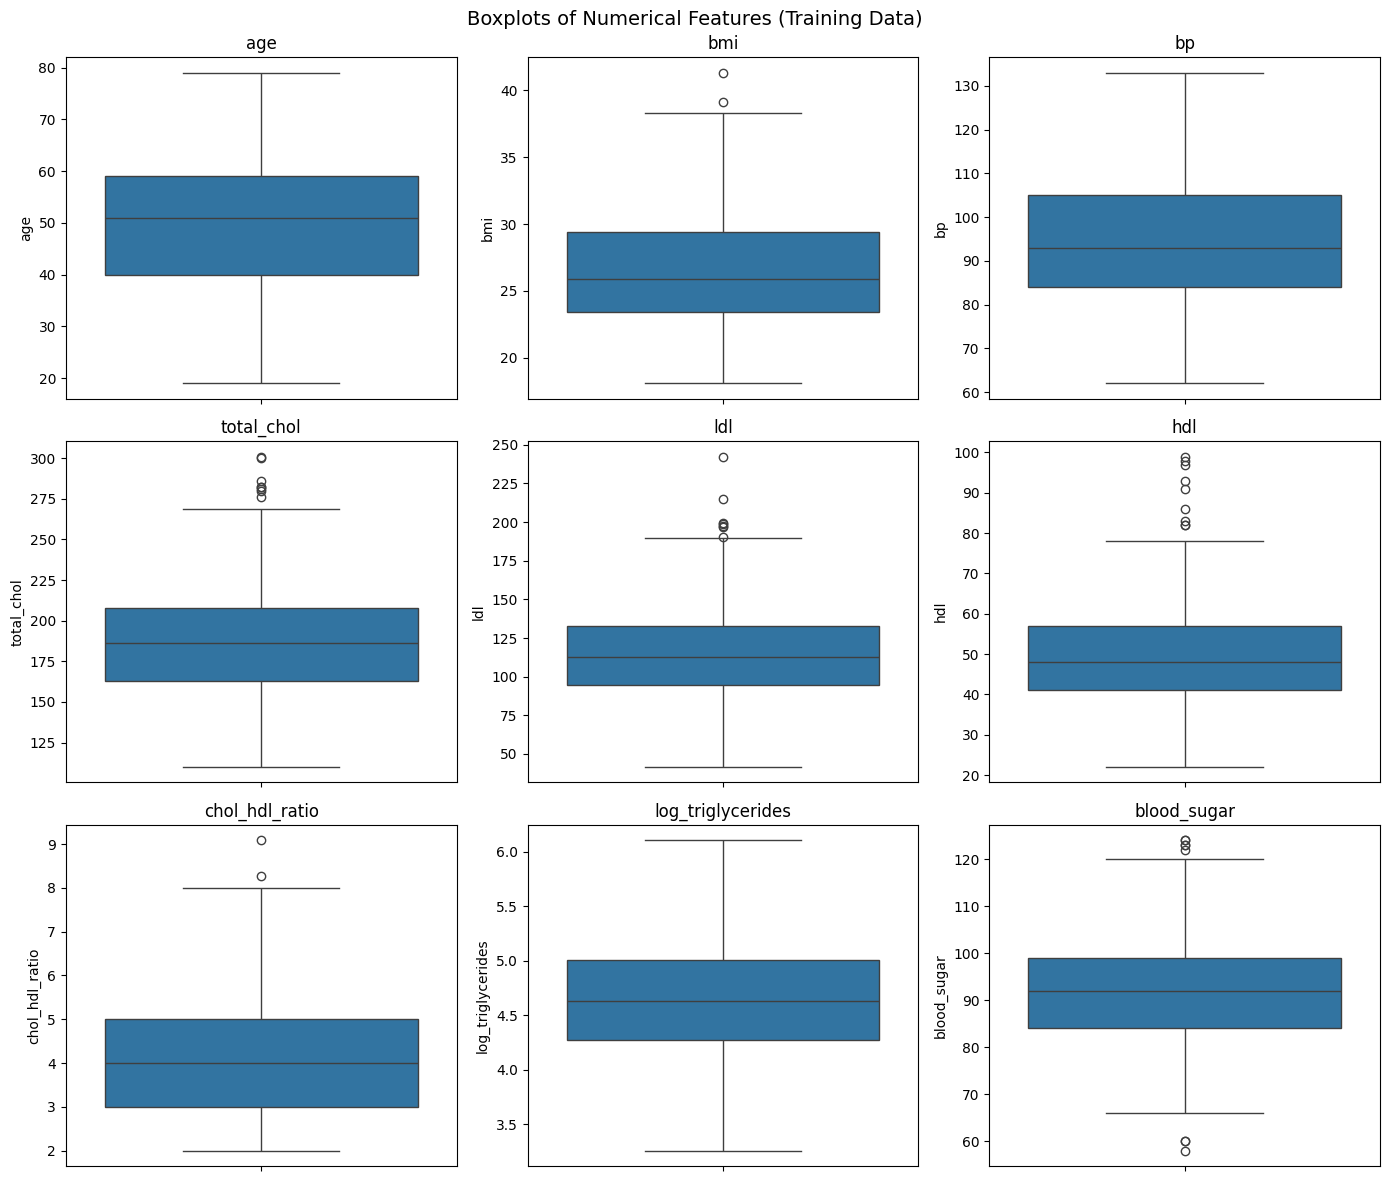

In [32]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=train_df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots of Numerical Features (Training Data)", fontsize=14)
plt.tight_layout()
plt.show()

In [21]:
for col in num_cols:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((train_df[col] < q1 - 1.5 * iqr) | (train_df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:18s} outliers: {n_out}")

age                outliers: 0
bmi                outliers: 2
bp                 outliers: 0
total_chol         outliers: 8
ldl                outliers: 7
hdl                outliers: 9
chol_hdl_ratio     outliers: 2
log_triglycerides  outliers: 0
blood_sugar        outliers: 8


### Interpretation: Outliers
Using the IQR rule on the training data:
- age, bp, and log_triglycerides have no outliers.
- bmi has 2 high outliers (around 39 and 41), and chol_hdl_ratio has 2 high outliers (around 8.3 and 9.1).
- total_chol (8), ldl (7), and hdl (9) have high outliers, and blood_sugar has 8 outliers on both the low side (around 58 to 60) and the high side (around 121 to 124).

All of these values are realistic for real patients (for example, a BMI of 41 or an HDL of 99 can happen), so they are likely real measurements rather than errors. Each column has at most 9 outliers out of 353 patients (under 3%).

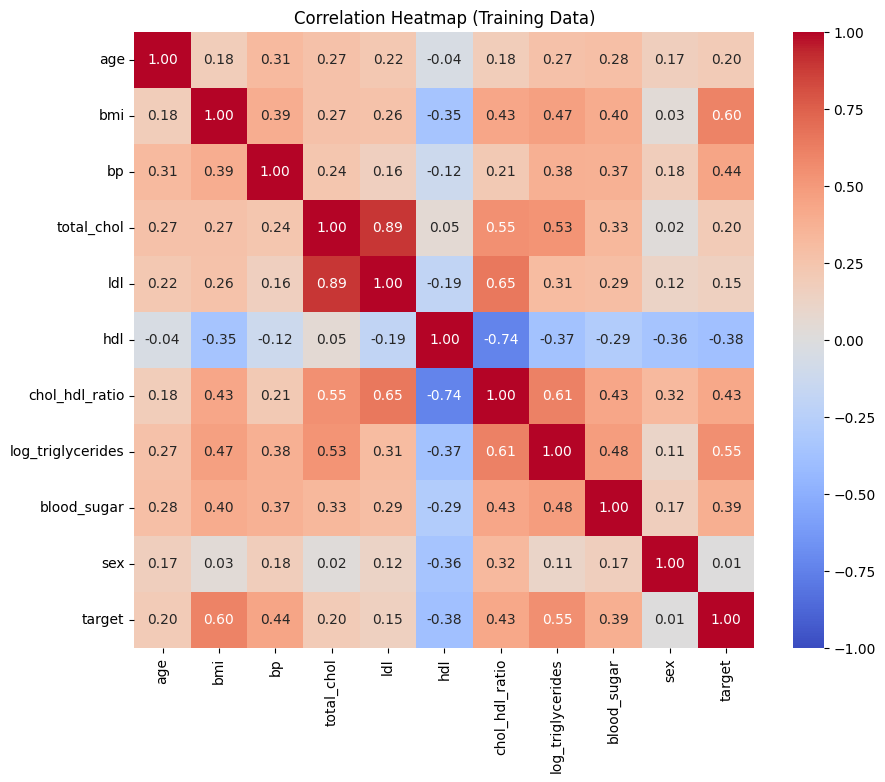

In [26]:
# 2. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(train_df[num_cols + ["sex", "target"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Training Data)")
plt.show()



### Interpretation: Correlation Heatmap

Relationships with disease progression:
- bmi has the strongest relationship (0.60), followed by log_triglycerides (0.55), bp (0.44), and chol_hdl_ratio (0.43). Higher values are linked to worse progression.
- hdl ("good" cholesterol) has a negative relationship (-0.38), so higher HDL is linked to less progression.
- blood_sugar has a moderate relationship (0.39).
- age (0.20), total_chol (0.20), and ldl (0.15) have weak relationships.
- sex has no relationship with progression (0.01).

Multicollinearity:
- total_chol and ldl are strongly correlated (0.89), because LDL is part of total cholesterol.
- chol_hdl_ratio is strongly related to hdl (-0.74) and ldl (0.65), because it is calculated from cholesterol values.
- These overlapping features may make Linear Regression coefficients unreliable, which Ridge and Lasso can help with. 

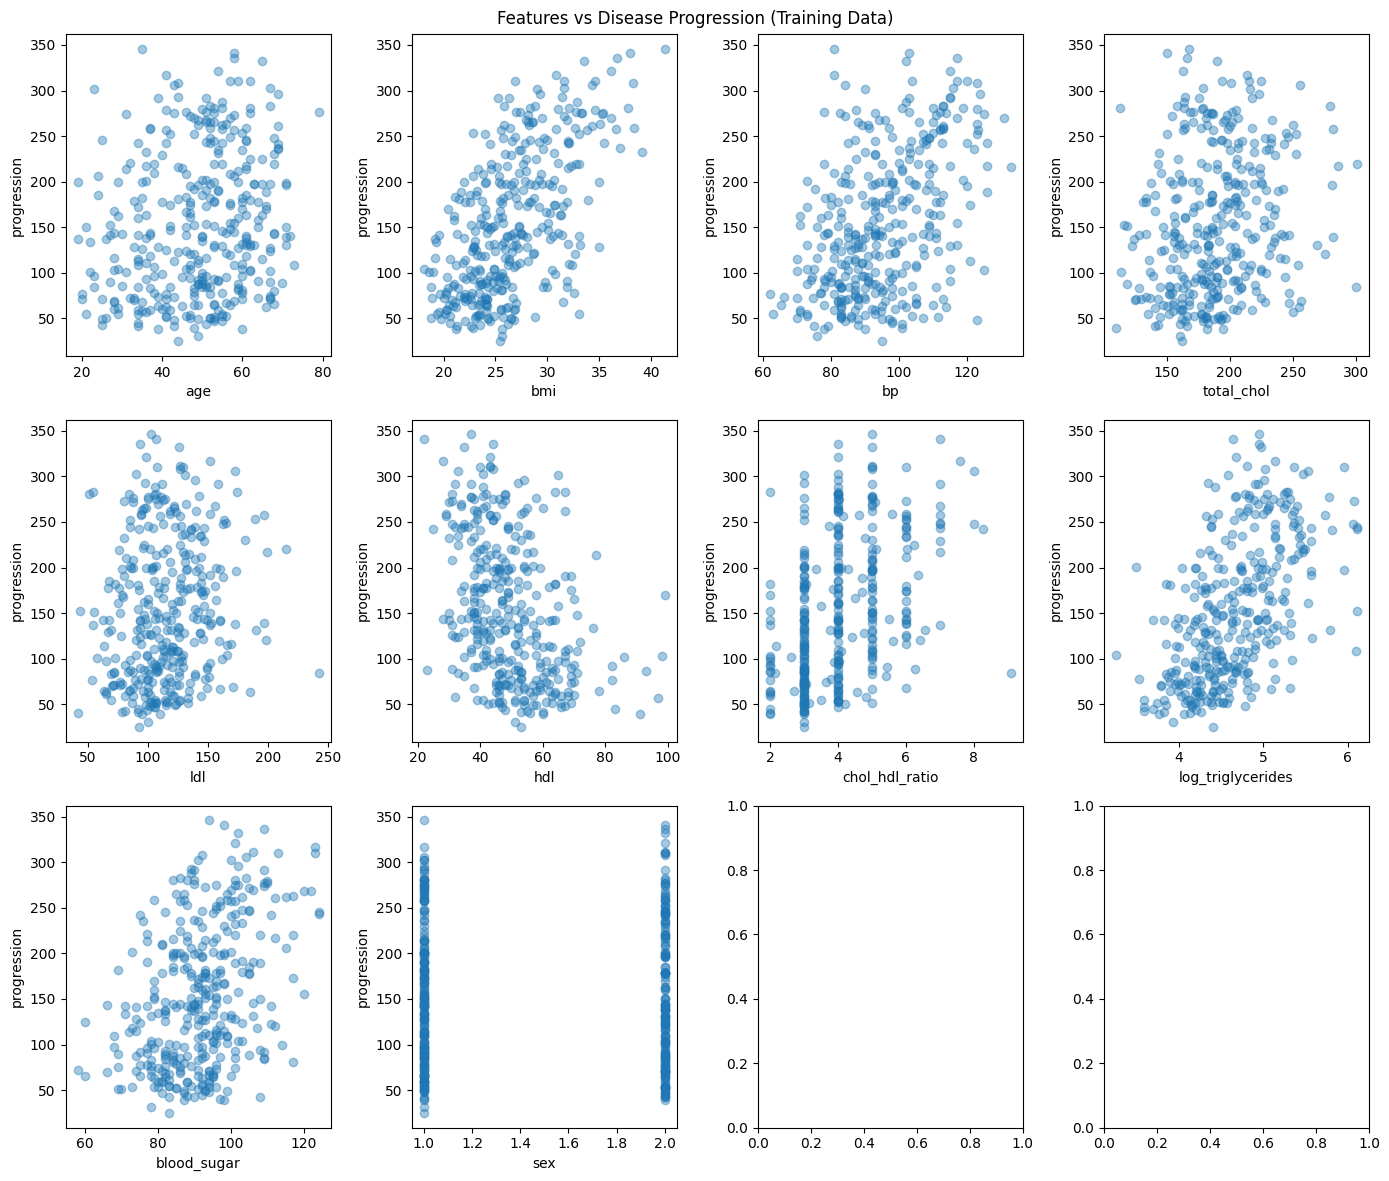

In [34]:
# 3. Each feature vs target
fig, axes = plt.subplots(3, 4, figsize=(14, 12))
for ax, col in zip(axes.flat, num_cols + ["sex"]):
    ax.scatter(train_df[col], train_df["target"], alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("progression")
plt.suptitle("Features vs Disease Progression (Training Data)")
plt.tight_layout()
plt.show()

### Interpretation: Features vs Disease Progression

- bmi and log_triglycerides show the clearest upward trends: patients with higher values tend to have worse progression.
- bp and blood_sugar show weaker upward trends with more spread.
- hdl shows a downward trend: higher HDL is linked to lower progression.
- age, total_chol, and ldl show very weak patterns, with points spread widely.
- chol_hdl_ratio forms vertical lines because its values are rounded to whole numbers.
- sex shows two columns (1 and 2) with very similar spreads, which confirms it has little effect on progression.
- Most relationships look roughly straight rather than curved, which suggests linear models may work reasonably well. However, the wide spread of points shows that no single feature can predict progression accurately on its own.

In [35]:
from sklearn.ensemble import IsolationForest

In [36]:
# 1. Group-wise z-scores: compare BMI and blood pressure to others in the same age group
for col in ["bmi", "bp", "blood_sugar"]:
    group_mean = train_df.groupby("age_group", observed=True)[col].transform("mean")
    group_std = train_df.groupby("age_group", observed=True)[col].transform("std")
    train_df[f"{col}_z_in_age"] = (train_df[col] - group_mean) / group_std

z_cols = ["bmi_z_in_age", "bp_z_in_age", "blood_sugar_z_in_age"]
unusual_for_age = train_df[(train_df[z_cols].abs() > 2.5).any(axis=1)]
print(f"Patients unusual for their age group (|z| > 2.5): {len(unusual_for_age)}")
display(unusual_for_age[["age", "age_group", "bmi", "bp", "blood_sugar", "target"] + z_cols].round(2))

Patients unusual for their age group (|z| > 2.5): 12


,age,age_group,bmi,bp,blood_sugar,target,bmi_z_in_age,bp_z_in_age,blood_sugar_z_in_age
114,55.0,51-60,36.6,113.00,97.0,258.0,2.55,1.28,0.29
23,61.0,61-70,32.0,103.67,124.0,245.0,1.09,0.18,2.84
262,44.0,41-50,38.2,123.00,92.0,308.0,2.71,1.74,0.05
428,62.0,61-70,34.6,120.00,123.0,310.0,1.72,1.31,2.74
406,33.0,31-40,18.9,70.00,58.0,72.0,-1.43,-1.59,-2.79
41,21.0,19-30,20.1,63.00,89.0,55.0,-0.83,-2.65,0.82
256,35.0,31-40,41.3,81.00,94.0,346.0,2.68,-0.73,0.34
32,58.0,51-60,38.0,103.00,98.0,341.0,2.91,0.46,0.38
138,58.0,51-60,36.7,117.00,109.0,336.0,2.57,1.61,1.37
350,41.0,41-50,32.0,126.00,124.0,243.0,1.27,1.92,2.51


### Interpretation: Multivariate Outliers

Some values look normal on their own but are unusual for that type of patient. For example, a BMI of 35 is common overall, but rare for a young person. To find these cases, I used two methods on the training data.

1. Comparing patients to others in their own age group
I compared each patient's BMI, blood pressure, and blood sugar with the average of their own age group. 12 patients were very different from others their age (more than 2.5 standard deviations away). Some examples:
- A 35-year-old with a BMI of 41.3, which is extremely high for that age group. This patient also has the highest disease progression in the training data (346).
- A 29-year-old with a BMI of 35, which is unusual for someone in their twenties.
- A 31-year-old with a blood pressure of 125, which is very high for that age.
- A 21-year-old with a blood pressure of 63, which is unusually low.
- Two patients in their sixties with very high blood sugar (123 to 124).

In [37]:
# 2. Isolation Forest on all numeric features
iso = IsolationForest(contamination=0.02, random_state=42)
train_df["iso_flag"] = iso.fit_predict(train_df[num_cols])
iso_outliers = train_df[train_df["iso_flag"] == -1]
print(f"\nIsolation Forest flagged {len(iso_outliers)} patients as unusual overall:")
display(iso_outliers[num_cols + ["target"]].round(2))


Isolation Forest flagged 8 patients as unusual overall:


,age,bmi,bp,total_chol,ldl,hdl,chol_hdl_ratio,log_triglycerides,blood_sugar,target
261,62.0,22.5,125.00,215.0,99.0,98.0,2.00,4.50,95.0,103.0
123,50.0,29.6,94.33,300.0,242.4,33.0,9.09,4.81,109.0,84.0
322,55.0,32.1,112.67,207.0,92.4,25.0,8.28,6.10,111.0,242.0
336,43.0,34.3,84.00,256.0,172.6,33.0,8.00,5.53,104.0,306.0
230,38.0,33.0,78.00,301.0,215.0,50.0,6.02,5.19,108.0,220.0
405,62.0,37.8,119.00,113.0,51.0,31.0,4.00,5.04,84.0,281.0
161,36.0,32.3,115.00,286.0,199.4,39.0,7.00,5.47,112.0,217.0
441,36.0,19.6,71.00,250.0,133.2,97.0,3.00,4.60,92.0,57.0


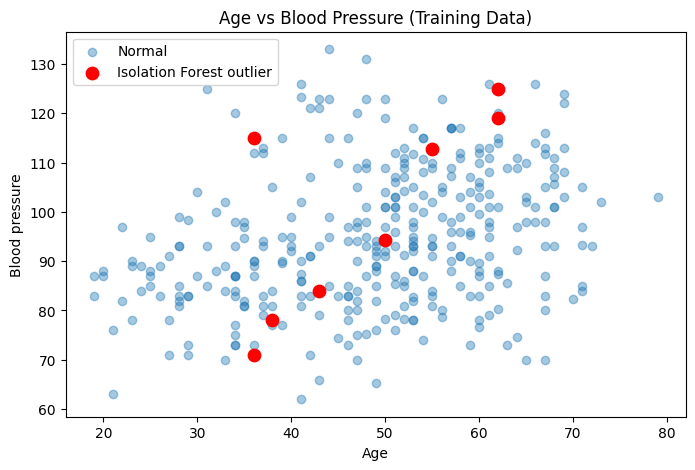

In [38]:
# 3. Visual check: age vs blood pressure, flagged patients in red
plt.figure(figsize=(8, 5))
normal = train_df[train_df["iso_flag"] == 1]
plt.scatter(normal["age"], normal["bp"], alpha=0.4, label="Normal")
plt.scatter(iso_outliers["age"], iso_outliers["bp"], color="red", s=80, label="Isolation Forest outlier")
plt.xlabel("Age")
plt.ylabel("Blood pressure")
plt.title("Age vs Blood Pressure (Training Data)")
plt.legend()
plt.show()

### 2. Isolation Forest (looking at all features together)
Isolation Forest looks at all 9 numeric features at the same time and finds patients who are very different from everyone else. It works by repeatedly splitting the data with random questions (for example, "Is HDL above 90?"). Unusual patients get separated from the group after only a few questions, while normal patients take many more.

It flagged 8 patients, mostly because of unusual cholesterol combinations. For example, one patient is 62 years old with a normal BMI (22.5), but has very high HDL ("good" cholesterol) of 98 and the lowest cholesterol/HDL ratio in the data (2.0). Each value is possible on its own, but together they make this patient very different from the others.

In the age vs blood pressure chart, most red points sit among the normal points. This is because the chart only shows 2 of the 9 features. These patients have normal age and blood pressure, and what makes them unusual is in other features, such as cholesterol.

## Decision:
I decided to keep all of these patients. Their values are unusual but medically possible, and several of them have high disease progression, so they contain useful information. Removing them would also reduce an already small dataset (353 training patients).

# Part 5: Data Cleaning

In [39]:
# Missing values (both sets)
print("Missing values - train:", X_train.isnull().sum().sum(), "| test:", X_test.isnull().sum().sum())



Missing values - train: 0 | test: 0


# Part 6: Feature Engineering

In [43]:
def add_features(data):
    data = data.copy()
    # Exact cholesterol ratio (the original column is rounded)
    data["chol_hdl_ratio"] = data["total_chol"] / data["hdl"]
    # Non-HDL cholesterol: all the "bad" cholesterol (used by doctors)
    data["non_hdl_chol"] = data["total_chol"] - data["hdl"]
    # BMI categories (fixed WHO cut-offs, not learned from data)
    data["overweight"] = ((data["bmi"] >= 25) & (data["bmi"] < 30)).astype(int)
    data["obese"] = (data["bmi"] >= 30).astype(int)
    # Interaction: high BMI and high blood pressure together
    data["bmi_x_bp"] = data["bmi"] * data["bp"]
    return data

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

print("Before:", X_train.shape, "| After:", X_train_fe.shape)

Before: (353, 10) | After: (353, 14)


In [44]:
# How do the new features relate to the target? (training data)
check = X_train_fe.copy()
check["target"] = y_train
new_cols = ["chol_hdl_ratio", "non_hdl_chol", "overweight", "obese", "bmi_x_bp"]
print("\nCorrelation with target:")
print(check[new_cols + ["bmi", "bp"]].corrwith(check["target"]).round(3).sort_values(ascending=False))


Correlation with target:
bmi_x_bp          0.637
bmi               0.605
bp                0.445
chol_hdl_ratio    0.435
obese             0.431
non_hdl_chol      0.326
overweight        0.114
dtype: float64


### Interpretation: Feature Engineering

I created new features based on the EDA and medical knowledge, using the same formulas on both the training and test sets:
- chol_hdl_ratio: recalculated exactly as total cholesterol divided by HDL, because the original column was rounded.
- non_hdl_chol: total cholesterol minus HDL, which measures all the "bad" cholesterol.
- overweight and obese: 0/1 flags based on the standard WHO BMI cut-offs (25 to 30 and 30 or more). The EDA showed disease progression rises sharply across these BMI groups.
- bmi_x_bp: BMI multiplied by blood pressure, to capture the combined effect of being heavier and having higher blood pressure.

This increased the features from 10 to 14. Checking their correlation with the target on the training data:
- bmi_x_bp has the strongest relationship of all features (0.637), higher than bmi (0.605) or blood pressure (0.445) alone.
- non_hdl_chol (0.326) is more strongly related to progression than total cholesterol (0.20) or LDL (0.15).
- obese (0.431) is a useful simple flag, while overweight (0.114) is weak on its own but works together with obese to capture the BMI groups.

I kept all new features. Lasso Regression, used later, can automatically reduce the effect of features that are not useful.

# Part 7: Model Selection and Training

In [45]:
models = {
    "Linear Regression (baseline)": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(random_state=42))]),
    "Lasso": Pipeline([("scaler", StandardScaler()), ("model", Lasso(random_state=42, max_iter=10000))]),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

def get_scores(name, model):
    model.fit(X_train_fe, y_train)
    pred_train = model.predict(X_train_fe)
    pred_test = model.predict(X_test_fe)
    return {
        "Model": name,
        "Train R²": round(r2_score(y_train, pred_train), 3),
        "Test R²": round(r2_score(y_test, pred_test), 3),
        "Test MSE": round(mean_squared_error(y_test, pred_test), 1),
        "Test RMSE": round(np.sqrt(mean_squared_error(y_test, pred_test)), 2),
        "Test MAE": round(mean_absolute_error(y_test, pred_test), 2)
    }

results = [get_scores(name, model) for name, model in models.items()]
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                       Model  Train R²  Test R²  Test MSE  Test RMSE  Test MAE
Linear Regression (baseline)     0.544    0.445    2938.1      54.20     43.12
                       Ridge     0.543    0.442    2956.7      54.38     43.44
                       Lasso     0.531    0.471    2800.4      52.92     42.57
               Decision Tree     1.000   -0.122    5946.2      77.11     60.17
               Random Forest     0.923    0.472    2799.3      52.91     42.85


### Interpretation

I trained five regression models with their default settings. The linear models used scaled features, while the tree models did not need scaling.

Results on the test set:
- Linear Regression (baseline): R² 0.445, RMSE 54.20, MAE 43.12
- Ridge: R² 0.442, RMSE 54.38, MAE 43.44
- Lasso: R² 0.471, RMSE 52.92, MAE 42.57
- Decision Tree: R² -0.122, RMSE 77.11, MAE 60.17
- Random Forest: R² 0.472, RMSE 52.91, MAE 42.85

Metrics:
- MSE (Mean Squared Error) is the average squared error, which is hard to read directly.
- RMSE (Root Mean Squared Error) is the typical prediction error in the same units as the target. For the best models, predictions are off by about 53 points.
- MAE (Mean Absolute Error) is the average size of the errors, about 43 points for the best models. It is lower than RMSE because RMSE gives more weight to large errors.
- R² shows how much of the variation in disease progression the model explains.

Findings:
- Lasso and Random Forest performed best, each explaining about 47% of the variation. Lasso slightly beat plain Linear Regression, because it reduces the effect of less useful and overlapping features.
- The Decision Tree overfit badly. It scored a perfect 1.00 on the training data, because it memorized every patient, but -0.12 on the test data, which is worse than predicting the average for everyone.
- The Random Forest also overfit (0.92 on training vs 0.47 on test), but averaging 100 trees made it much more stable than a single tree.
- The linear models showed only a small gap between training and test scores, so they overfit very little.
- An R² of around 0.47 is typical for this dataset, because disease progression also depends on factors that were not measured, such as diet, medication, and genetics.

### Model complexity vs interpretability
- Linear Regression, Ridge, and Lasso are simple and easy to explain. Each feature has one coefficient that shows how much it increases or decreases progression, which is useful for doctors.
- A single Decision Tree is easy to visualize as a flowchart, but it overfits easily.
- Random Forest is more complex. It combines 100 trees, which makes it accurate but much harder to explain, so it needs tools like feature importance or SHAP.
- Since Lasso performs as well as Random Forest here while being much easier to interpret, it is a strong choice for this problem.

# Part 8: Visualizing Model Performance

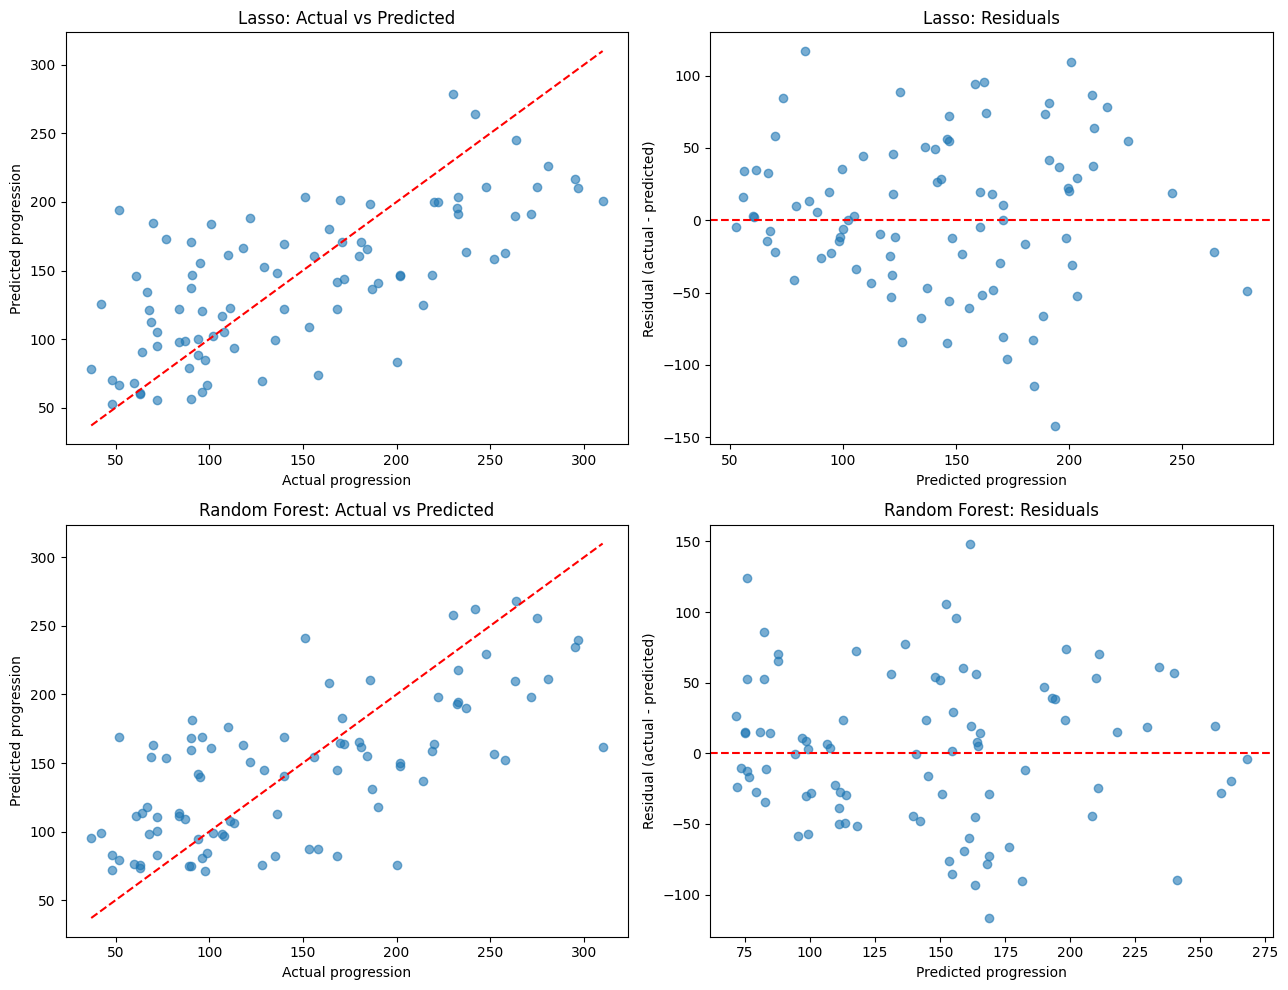

In [46]:
best_models = {"Lasso": models["Lasso"], "Random Forest": models["Random Forest"]}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (name, model) in enumerate(best_models.items()):
    pred = model.predict(X_test_fe)
    residuals = y_test - pred

    # Actual vs predicted
    ax = axes[row, 0]
    ax.scatter(y_test, pred, alpha=0.6)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    ax.set_xlabel("Actual progression")
    ax.set_ylabel("Predicted progression")
    ax.set_title(f"{name}: Actual vs Predicted")

    # Residuals vs predicted
    ax = axes[row, 1]
    ax.scatter(pred, residuals, alpha=0.6)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted progression")
    ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(f"{name}: Residuals")

plt.tight_layout()
plt.show()

### Interpretation

Actual vs predicted:
- For both Lasso and Random Forest, the points follow the red line loosely, so the models capture the general trend, but with a lot of spread.
- Both models pull their predictions towards the middle. Patients with low progression (around 50) are often predicted too high (around 100 to 150), and patients with high progression (around 300) are predicted too low (around 200 to 240). This happens because the features explain only about half of the variation, so the models avoid extreme predictions.
- Random Forest predictions stay in a narrower range (about 70 to 270) than the actual values (about 25 to 346).

Residuals (actual minus predicted):
- For both models, the residuals are scattered randomly above and below zero, with no clear funnel or curved pattern. This suggests the models are not missing an obvious pattern and the errors are fairly even across the range of predictions.
- However, the errors are large. Most residuals are within about ±50 points, but some reach about ±100 to ±140. This matches the RMSE of about 53 and shows the models can give a general estimate but are not precise for individual patients.

# Part 9: Hyperparameter Tuning and Optimization

In [47]:
param_grids = {
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 50, 100]},
    "Lasso": {"model__alpha": [0.01, 0.1, 0.5, 1, 2, 5]},
    "Decision Tree": {"max_depth": [2, 3, 4, 5, 6, None],
                      "min_samples_leaf": [1, 5, 10, 20]},
    "Random Forest": {"n_estimators": [100, 300],
                      "max_depth": [3, 5, 8, None],
                      "min_samples_leaf": [1, 5, 10]}
}

tuned_results = []
best_estimators = {}

for name, grid in param_grids.items():
    search = GridSearchCV(models[name], grid, cv=5, scoring="r2", n_jobs=-1)
    search.fit(X_train_fe, y_train)
    best_estimators[name] = search.best_estimator_
    pred = search.predict(X_test_fe)
    tuned_results.append({
        "Model": name,
        "Best parameters": search.best_params_,
        "CV R²": round(search.best_score_, 3),
        "Test R²": round(r2_score(y_test, pred), 3),
        "Test RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 2),
        "Test MAE": round(mean_absolute_error(y_test, pred), 2)
    })

In [48]:
# Linear Regression has no hyperparameters: add its CV score for comparison
lr_cv = cross_val_score(models["Linear Regression (baseline)"], X_train_fe, y_train, cv=5, scoring="r2").mean()
lr_pred = models["Linear Regression (baseline)"].predict(X_test_fe)
tuned_results.insert(0, {"Model": "Linear Regression (baseline)", "Best parameters": "-",
                         "CV R²": round(lr_cv, 3), "Test R²": round(r2_score(y_test, lr_pred), 3),
                         "Test RMSE": round(np.sqrt(mean_squared_error(y_test, lr_pred)), 2),
                         "Test MAE": round(mean_absolute_error(y_test, lr_pred), 2)})

tuned_df = pd.DataFrame(tuned_results)
print(tuned_df.to_string(index=False))

                       Model                                               Best parameters  CV R²  Test R²  Test RMSE  Test MAE
Linear Regression (baseline)                                                             -  0.462    0.445      54.20     43.12
                       Ridge                                          {'model__alpha': 10}  0.464    0.446      54.17     43.53
                       Lasso                                         {'model__alpha': 0.1}  0.464    0.447      54.14     43.28
               Decision Tree                      {'max_depth': 3, 'min_samples_leaf': 20}  0.309    0.340      59.13     48.12
               Random Forest {'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 100}  0.430    0.495      51.72     42.47


### Interpretation

I used GridSearchCV with 5-fold cross-validation on the training data to tune the hyperparameters of each model, then checked the best version once on the test set.

Best settings:
- Ridge: alpha = 10
- Lasso: alpha = 0.1
- Decision Tree: max_depth = 3, min_samples_leaf = 20
- Random Forest: max_depth = 8, min_samples_leaf = 10, n_estimators = 100

Results:
- Ridge and Lasso had the best cross-validation R² (0.464), followed closely by Linear Regression (0.462). On the test set they scored about 0.45, with an RMSE of about 54.
- The tuned Random Forest had a lower cross-validation R² (0.430) but the best test R² (0.495, RMSE 51.72).
- The tuned Decision Tree improved the most, from -0.12 to 0.34 on the test set. Limiting the tree to 3 levels and requiring at least 20 patients in each final group stopped it from memorizing the training data.

Choosing the best model:
I based my choice mainly on the cross-validation scores, because they use all 353 training patients across 5 rounds, while the test set has only 89 patients and can be affected by luck. For example, the default Lasso (alpha = 1) scored higher on the test set than the tuned Lasso (alpha = 0.1), even though cross-validation preferred 0.1. This shows how much a small test set can vary.

I selected Lasso Regression as my final model. It has the best cross-validation score, it barely overfits, and it is easy to interpret, because each feature has a clear coefficient. Random Forest is a close alternative with a slightly better test score, but it is more complex and harder to explain, and its cross-validation score was lower.

# Part 10: Interpretation - Impact of Features on Disease Progression

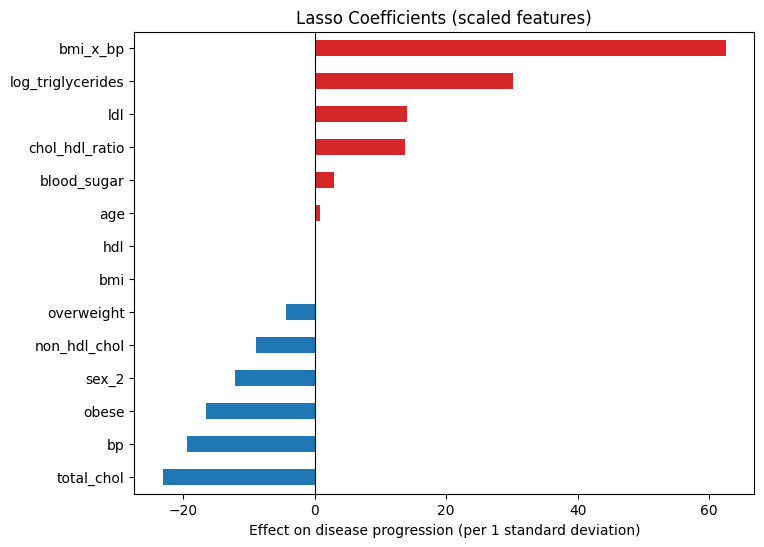

total_chol          -23.16
bp                  -19.43
obese               -16.52
sex_2               -12.09
non_hdl_chol         -9.00
overweight           -4.44
bmi                   0.00
hdl                   0.00
age                   0.83
blood_sugar           2.90
chol_hdl_ratio       13.69
ldl                  14.08
log_triglycerides    30.16
bmi_x_bp             62.59
dtype: float64

Features removed by Lasso (coefficient = 0): ['bmi', 'hdl']


In [49]:
# 1. Lasso coefficients (features were scaled, so the sizes can be compared)
final_model = best_estimators["Lasso"]
coefs = pd.Series(final_model.named_steps["model"].coef_, index=X_train_fe.columns).sort_values()

plt.figure(figsize=(8, 6))
colors = ["tab:red" if c > 0 else "tab:blue" for c in coefs]
coefs.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Lasso Coefficients (scaled features)")
plt.xlabel("Effect on disease progression (per 1 standard deviation)")
plt.show()
print(coefs.round(2))
print("\nFeatures removed by Lasso (coefficient = 0):", list(coefs[coefs == 0].index))


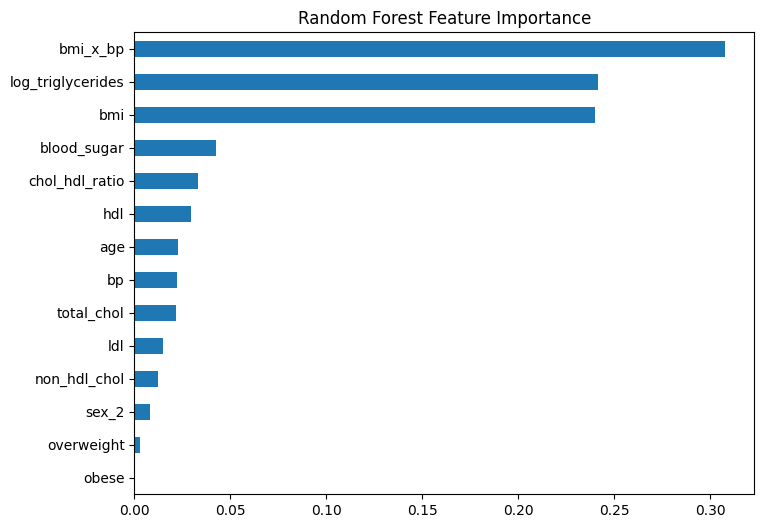

In [50]:
# 2. Random Forest feature importance (for comparison)
rf_imp = pd.Series(best_estimators["Random Forest"].feature_importances_,
                   index=X_train_fe.columns).sort_values()
rf_imp.plot(kind="barh", figsize=(8, 6), title="Random Forest Feature Importance")
plt.show()

### Interpretation: Impact of Features

Both the Lasso model and the Random Forest agree on the most important features:
- bmi_x_bp (BMI multiplied by blood pressure) is the strongest predictor in both models. Lasso gives it the largest coefficient (+62.6), and it has the highest Random Forest importance (0.31). Patients who are both heavier and have higher blood pressure tend to have much worse disease progression.
- log_triglycerides (blood fat level) is the second most important feature in both models (+30.2 in Lasso, 0.24 in Random Forest). Higher triglycerides are linked to faster progression.
- bmi on its own is the third most important feature in the Random Forest (0.24). In Lasso, its effect is already included in bmi_x_bp, so Lasso set the bmi coefficient to 0.
- Together, these three features make up about 80% of the Random Forest's importance. The other features, such as age, sex, and blood sugar, have much smaller effects.

Lasso feature selection:
Lasso removed two features by setting their coefficients to 0: bmi (its information is in bmi_x_bp) and hdl (its information is in chol_hdl_ratio and non_hdl_chol).

Unexpected signs:
Some Lasso coefficients are negative even though the EDA showed a positive relationship. For example, bp (-19.4) and obese (-16.5). This does not mean that high blood pressure or obesity reduce progression. Because bmi_x_bp already contains BMI and blood pressure, Lasso gave it a large positive effect and then balanced it with negative values on the related features. The cholesterol features (total_chol, ldl, non_hdl_chol, chol_hdl_ratio) also overlap, so their effects are split with mixed signs. This is caused by multicollinearity, so I rely on the overall picture and on the features that both models agree on, rather than on each individual coefficient.

Overall: body weight, blood pressure, and triglyceride levels are the strongest predictors of how quickly diabetes progresses.

# Ethical Considerations

- Not a medical decision tool: the model explains only about 45% to 50% of the variation and is often off by about 50 points. It should only support doctors, never replace their judgement.
- Small and limited data: the dataset has only 442 patients from one study. The results may not apply to other populations, ages, or ethnic groups, which could lead to unfair or wrong predictions for people who are not well represented.
- Fairness: sex is included as a feature. Any model used in practice should be checked to make sure it does not perform worse for one group than another.
- Correlation is not causation: the model shows that high BMI and triglycerides are linked to faster progression, but it does not prove they cause it. Treatment decisions should be based on medical research, not on model coefficients.
- Privacy: health data is very sensitive. Real patient data must be anonymized, stored securely, and used with consent.
- Transparency: I chose Lasso partly because it is easy to explain. In healthcare, patients and doctors should be able to understand why a prediction was made.

# Project Report

## Objective
The goal of this project was to build a regression model that predicts disease progression one year after baseline for diabetes patients, using the Diabetes dataset from scikit-learn, and to understand which factors affect progression the most.

## Methodology
- Loaded the unscaled version of the dataset (442 patients, 10 features) so the values were in real units, and renamed the six blood measurements to meaningful names.
- Checked for missing values and duplicates (none found), then split the data into 80% training (353) and 20% testing (89), before any exploration.
- Explored only the training data: summary statistics, value counts, target distribution, age groups, WHO BMI categories, logical consistency checks, univariate outliers (IQR), multivariate outliers (age-group z-scores and Isolation Forest), correlations, and feature vs target plots.
- Cleaned the data by converting sex into a 0/1 column. I kept all outliers, as they were realistic patient values.
- Created new features: an exact cholesterol/HDL ratio, non-HDL cholesterol, overweight and obese flags, and BMI x blood pressure.
- Trained Linear Regression (baseline), Ridge, Lasso, Decision Tree, and Random Forest models, with scaling inside a Pipeline for the linear models.
- Evaluated the models with MSE, RMSE, MAE, and R², and used actual vs predicted and residual plots.
- Tuned the models with GridSearchCV (5-fold cross-validation on the training data) and selected the final model mainly based on cross-validation scores.
- Interpreted feature impact using Lasso coefficients and Random Forest feature importance.

## Key findings
- BMI had the strongest single relationship with progression (0.60). Progression roughly doubled from normal-weight patients (108) to obese patients (217), and it also increased with age.
- All cholesterol values passed the logical checks, and the original cholesterol ratio was found to be rounded.
- The engineered feature bmi_x_bp became the strongest predictor in both Lasso and Random Forest.
- Ridge and Lasso had the best cross-validation R² (0.464). The tuned Random Forest had the best test R² (0.495). The Decision Tree overfit badly until it was tuned.
- I selected Lasso (alpha = 0.1) as the final model because of its strong cross-validation score, low overfitting, and interpretability. Its test performance was R² 0.447, RMSE 54.14, and MAE 43.28.
- The most important factors for disease progression were the combination of BMI and blood pressure, triglyceride levels, and BMI.

## Limitations and potential improvements
- The dataset is small (442 patients), and the features explain only about half of the variation in progression. Important factors such as diet, medication, physical activity, and genetics are not included.
- The models pull predictions towards the middle, so very mild and very severe cases are predicted less accurately.
- Several features overlap (multicollinearity), which makes some individual coefficients hard to interpret.
- Possible improvements: collect more patients and more types of features, try other models such as Gradient Boosting, use repeated cross-validation for a more stable comparison, and use SHAP to explain individual predictions.

## Reproducibility
All steps use random_state=42, all transformations were learned from the training data only, and the notebook runs from top to bottom without errors.